# Tennis Court Keypoint Detector — Training Notebook

This notebook walks you through training a CNN to detect 14 tennis court keypoints from broadcast video frames.

Based on [TennisCourtDetector by yastrebksv](https://github.com/yastrebksv/TennisCourtDetector).

## Architecture
- **Model**: TrackNet-style encoder-decoder (VGG-like conv blocks → 3× downsample → 3× upsample)
- **Input**: 640×360 RGB image
- **Output**: 15-channel heatmap (14 keypoints + 1 court center)
- **Loss**: MSE between predicted sigmoid heatmaps and ground-truth Gaussian heatmaps

## 14 Keypoints
```
0 ●──────────────────● 1      Far baseline
  │  4 ●────────● 6  │
  │    │ 8    9 │    │      Far service line
  │    │   12   │    │      Center service line
  │    │   13   │    │
  │    │10   11 │    │      Near service line
  │  5 ●────────● 7  │
2 ●──────────────────● 3      Near baseline
```

## 1. Setup & Dependencies

In [2]:
# Install dependencies (run once)
# %pip install torch torchvision opencv-python numpy matplotlib gdown sympy scipy

In [2]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')
print(f'PyTorch version: {torch.__version__}')

Using device: cuda
PyTorch version: 2.11.0+cu128


## 2. Download the Dataset

The dataset has 8841 images (1280×720) with 14 annotated keypoints each, split 75/25 train/val.

Download from: https://drive.google.com/file/d/1lhAaeQCmk2y440PmagA0KmIVBIysVMwu/view

Extract into `data/` so you have:
```
data/
  images/
    *.png
  data_train.json
  data_val.json
```

Each JSON entry: `{"id": "image_name", "kps": [[x0,y0], [x1,y1], ... [x13,y13]]}`

In [3]:
DATA_DIR = os.path.join('data', 'data')  # notebooks/data/data/ (contains images/, data_train.json, data_val.json)

# Uncomment to download via gdown:
# import gdown
# gdown.download(id='1lhAaeQCmk2y440PmagA0KmIVBIysVMwu', output='dataset.zip')
# import zipfile
# with zipfile.ZipFile('dataset.zip', 'r') as z:
#     z.extractall(DATA_DIR)

# Verify dataset exists
for f in ['data_train.json', 'data_val.json']:
    path = os.path.join(DATA_DIR, f)
    if os.path.isfile(path):
        with open(path) as fh:
            d = json.load(fh)
        print(f'{f}: {len(d)} samples')
    else:
        print(f'⚠ {path} not found — download the dataset first')

data_train.json: 6630 samples
data_val.json: 2211 samples


## 3. Utility Functions

Gaussian heatmap drawing, line intersection, etc.

In [4]:
def gaussian2D(shape, sigma=1):
    """Create a 2D Gaussian kernel."""
    m, n = [(ss - 1.) / 2. for ss in shape]
    y, x = np.ogrid[-m:m+1, -n:n+1]
    h = np.exp(-(x * x + y * y) / (2 * sigma * sigma))
    h[h < np.finfo(h.dtype).eps * h.max()] = 0
    return h


def draw_umich_gaussian(heatmap, center, radius, k=1):
    """Draw a Gaussian blob on a heatmap at the given center."""
    diameter = 2 * radius + 1
    gaussian = gaussian2D((diameter, diameter), sigma=diameter / 6)

    x, y = int(center[0]), int(center[1])
    height, width = heatmap.shape[0:2]

    left, right = min(x, radius), min(width - x, radius + 1)
    top, bottom = min(y, radius), min(height - y, radius + 1)

    masked_heatmap = heatmap[y - top:y + bottom, x - left:x + right]
    masked_gaussian = gaussian[radius - top:radius + bottom, radius - left:radius + right]
    if min(masked_gaussian.shape) > 0 and min(masked_heatmap.shape) > 0:
        np.maximum(masked_heatmap, masked_gaussian * k, out=masked_heatmap)
    return heatmap


def line_intersection(line1, line2):
    """Find intersection point of two lines defined as (x1,y1,x2,y2)."""
    from sympy import Line as SympyLine
    import sympy
    l1 = SympyLine((line1[0], line1[1]), (line1[2], line1[3]))
    l2 = SympyLine((line2[0], line2[1]), (line2[2], line2[3]))
    intersection = l1.intersection(l2)
    if len(intersection) > 0 and isinstance(intersection[0], sympy.geometry.point.Point2D):
        return intersection[0].coordinates
    return None


def is_point_in_image(x, y, w=1280, h=720):
    """Check if a point is within image bounds."""
    return x is not None and y is not None and 0 <= x <= w and 0 <= y <= h


print('Utilities loaded.')

Utilities loaded.


## 4. Court Reference

14 reference keypoint positions in a synthetic court diagram coordinate system. These are used for:
- Computing the 15th heatmap channel (court center = diagonal intersection)
- Homography-based postprocessing

In [5]:
COURT_REF_KPS = [
    (286, 561), (1379, 561),       # 0-1: far baseline left, right
    (286, 2935), (1379, 2935),     # 2-3: near baseline left, right
    (423, 561), (423, 2935),       # 4-5: left singles sideline top, bottom
    (1242, 561), (1242, 2935),     # 6-7: right singles sideline top, bottom
    (423, 1110), (1242, 1110),     # 8-9: far service line left, right
    (423, 2386), (1242, 2386),     # 10-11: near service line left, right
    (832, 1110), (832, 2386),      # 12-13: center service line top, bottom
]

# 12 court configurations (4-point subsets for homography)
COURT_CONF_IND = {
    1:  [0, 1, 2, 3],    # full outer court
    2:  [4, 6, 5, 7],    # singles box
    3:  [4, 1, 5, 3],    # left singles + right outer
    4:  [0, 6, 2, 7],    # left outer + right singles
    5:  [8, 9, 10, 11],  # service boxes
    6:  [8, 9, 5, 7],    # far service + near singles
    7:  [4, 6, 10, 11],  # far singles + near service
    8:  [6, 1, 7, 3],    # right side
    9:  [0, 4, 2, 5],    # left side
    10: [8, 12, 10, 13], # left service boxes
    11: [12, 9, 13, 11], # right service boxes
    12: [10, 11, 5, 7],  # near service + bottom singles
}

print(f'{len(COURT_REF_KPS)} reference keypoints, {len(COURT_CONF_IND)} homography configurations')

14 reference keypoints, 12 homography configurations


## 5. Dataset

Each sample:
- **Input**: 640×360 RGB image normalized to [0,1]
- **Target**: 15 heatmaps (640×360) — one Gaussian blob per keypoint + court center
- Gaussian radius = 55 pixels (on the 640×360 output)

In [ ]:
class CourtDataset(Dataset):
    def __init__(self, mode, data_dir, input_h=720, input_w=1280, scale=2, hp_radius=55):
        assert mode in ['train', 'val']
        self.mode = mode
        self.input_h = input_h
        self.input_w = input_w
        self.out_h = input_h // scale
        self.out_w = input_w // scale
        self.scale = scale
        self.hp_radius = hp_radius
        self.num_joints = 14

        self.images_dir = os.path.join(data_dir, 'images')
        with open(os.path.join(data_dir, f'data_{mode}.json'), 'r') as f:
            self.data = json.load(f)

        # Precompute court centers (avoids slow sympy call in __getitem__)
        self.centers = []
        for entry in self.data:
            kps = entry['kps']
            ct = line_intersection(
                (kps[0][0], kps[0][1], kps[3][0], kps[3][1]),
                (kps[1][0], kps[1][1], kps[2][0], kps[2][1]),
            )
            self.centers.append(ct)
        print(f'[{mode}] {len(self.data)} samples (centers precomputed)')

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        entry = self.data[idx]
        img_name = entry['id'] + '.png'
        kps = entry['kps']  # list of 14 [x, y] pairs

        # Load and resize image to output resolution
        img = cv2.imread(os.path.join(self.images_dir, img_name))
        img = cv2.resize(img, (self.out_w, self.out_h))
        inp = (img.astype(np.float32) / 255.0)
        inp = np.rollaxis(inp, 2, 0)  # HWC → CHW

        # Build heatmap targets
        hm = np.zeros((self.num_joints + 1, self.out_h, self.out_w), dtype=np.float32)
        for i in range(len(kps)):
            kx, ky = kps[i]
            if 0 <= kx <= self.input_w and 0 <= ky <= self.input_h:
                x_sc = int(kx / self.scale)
                y_sc = int(ky / self.scale)
                draw_umich_gaussian(hm[i], (x_sc, y_sc), self.hp_radius)

        # 15th channel: court center (precomputed)
        ct = self.centers[idx]
        if ct is not None:
            draw_umich_gaussian(hm[self.num_joints], (int(ct[0] / self.scale), int(ct[1] / self.scale)), self.hp_radius)

        return inp, hm, np.array(kps, dtype=int), img_name[:-4]


# Quick test
if os.path.isfile(os.path.join(DATA_DIR, 'data_train.json')):
    _ds = CourtDataset('train', DATA_DIR)
    print(f'Sample 0 — input: {_ds[0][0].shape}, heatmaps: {_ds[0][1].shape}, kps: {_ds[0][2].shape}')
else:
    print('Dataset not found — skipping test')

[train] 6630 samples
Sample 0 — input: (3, 360, 640), heatmaps: (15, 360, 640), kps: (14, 2)


### 5.1 Visualize a Sample

Look at an image with its keypoints and the generated heatmaps.

[train] 6630 samples


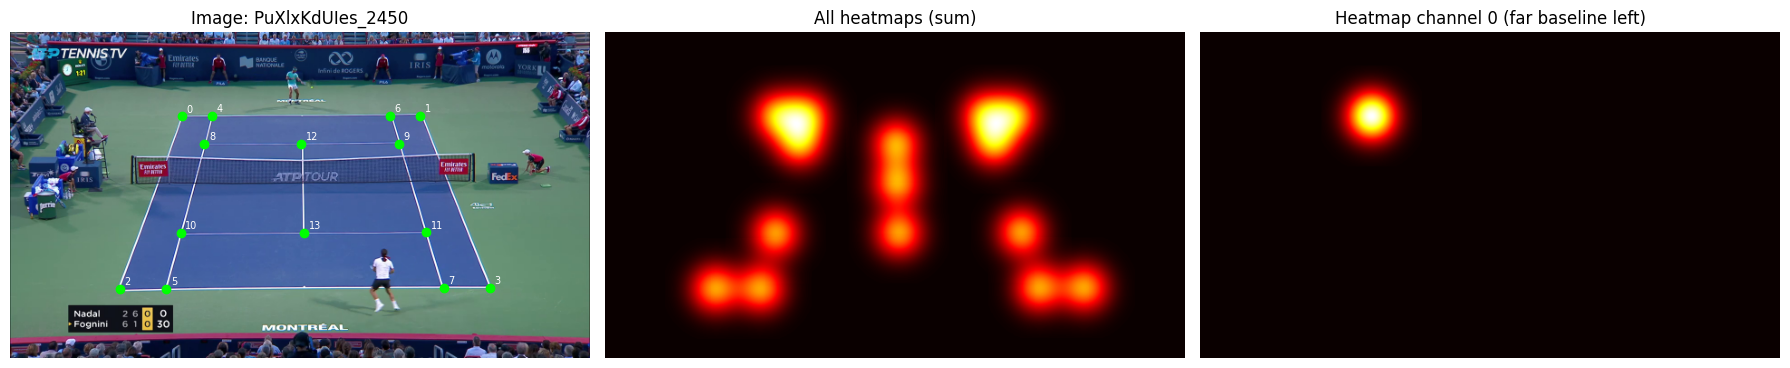

In [7]:
def visualize_sample(ds, idx=0):
    inp, hm, kps, name = ds[idx]
    img = np.rollaxis(inp, 0, 3)  # CHW → HWC

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Image with keypoints
    axes[0].imshow(img[..., ::-1])  # BGR → RGB
    for i, (x, y) in enumerate(kps):
        sx, sy = x // 2, y // 2  # scale to 640x360
        axes[0].plot(sx, sy, 'o', color='lime', markersize=6)
        axes[0].annotate(str(i), (sx + 5, sy - 5), color='white', fontsize=7)
    axes[0].set_title(f'Image: {name}')
    axes[0].axis('off')

    # Sum of all heatmaps
    axes[1].imshow(hm.sum(axis=0), cmap='hot')
    axes[1].set_title('All heatmaps (sum)')
    axes[1].axis('off')

    # Single heatmap (keypoint 0)
    axes[2].imshow(hm[0], cmap='hot')
    axes[2].set_title('Heatmap channel 0 (far baseline left)')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

if os.path.isfile(os.path.join(DATA_DIR, 'data_train.json')):
    visualize_sample(CourtDataset('train', DATA_DIR), idx=0)

## 6. Model Architecture

TrackNet-style encoder-decoder:
- **Encoder**: 10 conv blocks with 3 max-pool layers (3× downsampling to 80×45)
- **Decoder**: 3 upsample layers back to 640×360
- **Output**: 15 channels (sigmoid applied during loss computation)

In [8]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, pad=1, stride=1, bias=True):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, stride=stride, padding=pad, bias=bias),
            nn.ReLU(),
            nn.BatchNorm2d(out_ch),
        )

    def forward(self, x):
        return self.block(x)


class BallTrackerNet(nn.Module):
    """TrackNet-style encoder-decoder for court keypoint heatmap regression."""

    def __init__(self, out_channels=15):
        super().__init__()
        self.out_channels = out_channels

        # Encoder (64 → 128 → 256 → 512)
        self.conv1  = ConvBlock(3, 64)
        self.conv2  = ConvBlock(64, 64)
        self.pool1  = nn.MaxPool2d(2, 2)    # /2
        self.conv3  = ConvBlock(64, 128)
        self.conv4  = ConvBlock(128, 128)
        self.pool2  = nn.MaxPool2d(2, 2)    # /4
        self.conv5  = ConvBlock(128, 256)
        self.conv6  = ConvBlock(256, 256)
        self.conv7  = ConvBlock(256, 256)
        self.pool3  = nn.MaxPool2d(2, 2)    # /8
        self.conv8  = ConvBlock(256, 512)
        self.conv9  = ConvBlock(512, 512)
        self.conv10 = ConvBlock(512, 512)

        # Decoder (512 → 256 → 128 → 64 → out_channels)
        self.ups1   = nn.Upsample(scale_factor=2)  # ×2
        self.conv11 = ConvBlock(512, 256)
        self.conv12 = ConvBlock(256, 256)
        self.conv13 = ConvBlock(256, 256)
        self.ups2   = nn.Upsample(scale_factor=2)  # ×4
        self.conv14 = ConvBlock(256, 128)
        self.conv15 = ConvBlock(128, 128)
        self.ups3   = nn.Upsample(scale_factor=2)  # ×8 → full res
        self.conv16 = ConvBlock(128, 64)
        self.conv17 = ConvBlock(64, 64)
        self.conv18 = ConvBlock(64, out_channels)

        self._init_weights()

    def forward(self, x):
        # Encoder
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.pool1(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.pool2(x)
        x = self.conv5(x)
        x = self.conv6(x)
        x = self.conv7(x)
        x = self.pool3(x)
        x = self.conv8(x)
        x = self.conv9(x)
        x = self.conv10(x)
        # Decoder
        x = self.ups1(x)
        x = self.conv11(x)
        x = self.conv12(x)
        x = self.conv13(x)
        x = self.ups2(x)
        x = self.conv14(x)
        x = self.conv15(x)
        x = self.ups3(x)
        x = self.conv16(x)
        x = self.conv17(x)
        x = self.conv18(x)
        return x

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.uniform_(m.weight, -0.05, 0.05)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)


# Quick summary
model = BallTrackerNet(out_channels=15).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f'Model parameters: {total_params:,}')
print(f'Approx size: {total_params * 4 / 1024 / 1024:.1f} MB (float32)')

Model parameters: 10,565,037
Approx size: 40.3 MB (float32)


## 7. Training Loop

In [9]:
def train_one_epoch(model, loader, optimizer, criterion, device, epoch, max_steps=1000):
    model.train()
    losses = []
    max_steps = min(max_steps, len(loader))

    for step, (inp, gt_hm, kps, names) in enumerate(loader):
        if step >= max_steps:
            break

        inp = inp.float().to(device)
        gt_hm = gt_hm.float().to(device)

        pred = model(inp)
        loss = criterion(torch.sigmoid(pred), gt_hm)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if step % 100 == 0:
            print(f'  Epoch {epoch} step {step}/{max_steps} loss={loss.item():.6f}')

    return np.mean(losses)

print('Training function defined.')

Training function defined.


## 8. Validation Loop

A keypoint is "correct" if euclidean distance to ground truth < 7 pixels (on the 1280×720 scale).

In [10]:
from scipy.spatial import distance


def postprocess_heatmap(heatmap, scale=2, low_thresh=155, min_radius=10, max_radius=30):
    """Extract a keypoint (x, y) from a predicted heatmap channel."""
    _, binary = cv2.threshold(heatmap, low_thresh, 255, cv2.THRESH_BINARY)
    circles = cv2.HoughCircles(
        binary, cv2.HOUGH_GRADIENT, dp=1, minDist=20,
        param1=50, param2=2, minRadius=min_radius, maxRadius=max_radius,
    )
    if circles is not None:
        return float(circles[0][0][0]) * scale, float(circles[0][0][1]) * scale
    return None, None


def validate(model, loader, criterion, device, epoch, max_dist=7):
    model.eval()
    losses = []
    tp, fp, fn, tn = 0, 0, 0, 0

    with torch.no_grad():
        for inp, gt_hm, kps, names in loader:
            inp = inp.float().to(device)
            gt_hm_dev = gt_hm.float().to(device)
            pred = model(inp)
            loss = criterion(torch.sigmoid(pred), gt_hm_dev)
            losses.append(loss.item())

            pred_np = torch.sigmoid(pred).cpu().numpy()
            bs = pred_np.shape[0]

            for b in range(bs):
                for k in range(14):
                    heatmap = (pred_np[b][k] * 255).astype(np.uint8)
                    x_pred, y_pred = postprocess_heatmap(heatmap)
                    x_gt = kps[b][k][0].item()
                    y_gt = kps[b][k][1].item()

                    pred_in = is_point_in_image(x_pred, y_pred)
                    gt_in = is_point_in_image(x_gt, y_gt)

                    if pred_in and gt_in:
                        dst = distance.euclidean((x_pred, y_pred), (x_gt, y_gt))
                        if dst < max_dist:
                            tp += 1
                        else:
                            fp += 1
                    elif pred_in and not gt_in:
                        fp += 1
                    elif not pred_in and gt_in:
                        fn += 1
                    else:
                        tn += 1

    eps = 1e-15
    precision = tp / (tp + fp + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    print(f'  Val epoch {epoch}: loss={np.mean(losses):.6f} '
          f'tp={tp} fp={fp} fn={fn} tn={tn} '
          f'precision={precision:.4f} accuracy={accuracy:.4f}')

    return np.mean(losses), tp, fp, fn, tn, precision, accuracy

print('Validation function defined.')

Validation function defined.


## 9. Train!

Default hyperparameters from the original repo:
- **Batch size**: 2 (fit on most GPUs; increase if you have VRAM)
- **Learning rate**: 1e-5 (Adam)
- **Epochs**: 500 (validate every 5)
- **Steps per epoch**: 1000

Adjust these as needed. On CPU this will be very slow — GPU recommended.

In [ ]:
# ═══ Hyperparameters ═══
BATCH_SIZE = 8
LEARNING_RATE = 1e-5
NUM_EPOCHS = 50
VAL_INTERVAL = 5
STEPS_PER_EPOCH = 1000
SAVE_DIR = os.path.join('..', 'note', 'models')  # saves into the app's models folder
os.makedirs(SAVE_DIR, exist_ok=True)

print(f'Training config: batch={BATCH_SIZE}, lr={LEARNING_RATE}, epochs={NUM_EPOCHS}')
print(f'Will save to: {os.path.abspath(SAVE_DIR)}')

Training config: batch=6, lr=1e-05, epochs=500
Will save to: c:\repos\tennis-3d\note\models


In [ ]:
# ═══ Create data loaders ═══
train_ds = CourtDataset('train', DATA_DIR)
val_ds = CourtDataset('val', DATA_DIR)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f'Train: {len(train_ds)} samples → {len(train_loader)} batches')
print(f'Val:   {len(val_ds)} samples → {len(val_loader)} batches')

[train] 6630 samples
[val] 2211 samples
Train: 6630 samples → 1105 batches
Val:   2211 samples → 369 batches


In [13]:
# ═══ Model, optimizer, loss ═══
model = BallTrackerNet(out_channels=15).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.999))

best_accuracy = 0
train_losses = []
val_accuracies = []

print(f'Ready to train on {device}')

Ready to train on cuda


In [ ]:
# ═══ Training loop ═══
for epoch in range(NUM_EPOCHS):
    loss = train_one_epoch(model, train_loader, optimizer, criterion, device, epoch, STEPS_PER_EPOCH)
    train_losses.append(loss)
    print(f'Epoch {epoch}: train_loss={loss:.6f}')

    if epoch > 0 and epoch % VAL_INTERVAL == 0:
        val_loss, tp, fp, fn, tn, precision, accuracy = validate(model, val_loader, criterion, device, epoch)
        val_accuracies.append((epoch, accuracy))

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'court_detection_model_best.pth'))
            print(f'  ★ New best accuracy: {accuracy:.4f} — model saved')

    # Always save latest
    torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'court_detection_model.pth'))

print(f'\nTraining complete. Best accuracy: {best_accuracy:.4f}')

## 10. Training Curves

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.set_title('Training Loss')
ax1.grid(True)

if val_accuracies:
    epochs, accs = zip(*val_accuracies)
    ax2.plot(epochs, accs, 'o-')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Validation Accuracy')
    ax2.grid(True)

plt.tight_layout()
plt.show()

## 11. Inference on a Test Image

Load the trained model and visualize predictions on a frame.

In [ ]:
def predict_keypoints(model, frame_bgr, device='cpu'):
    """Run inference on a single BGR frame. Returns list of 14 (x, y) in original coords."""
    h, w = frame_bgr.shape[:2]
    img = cv2.resize(frame_bgr, (640, 360))
    inp = (img.astype(np.float32) / 255.0)
    inp = np.rollaxis(inp, 2, 0)  # CHW
    inp_t = torch.from_numpy(inp).unsqueeze(0).float().to(device)

    model.eval()
    with torch.no_grad():
        pred = torch.sigmoid(model(inp_t)).cpu().numpy()[0]

    points = []
    for i in range(14):
        heatmap = (pred[i] * 255).astype(np.uint8)
        x, y = postprocess_heatmap(heatmap, scale=1)  # scale=1 since we work at 640x360
        if x is not None:
            x = x * w / 640
            y = y * h / 360
        points.append((x, y))
    return points


def visualize_predictions(frame_bgr, points, title='Predictions'):
    """Draw predicted keypoints on a frame."""
    fig, ax = plt.subplots(1, 1, figsize=(12, 7))
    ax.imshow(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))

    for i, (x, y) in enumerate(points):
        if x is not None and y is not None:
            ax.plot(x, y, 'o', color='lime', markersize=8, markeredgecolor='white', markeredgewidth=1.5)
            ax.annotate(str(i), (x + 8, y - 8), color='yellow', fontsize=8, fontweight='bold')

    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

print('Inference functions defined.')

In [ ]:
# Load the best model and test on a sample
model_path = os.path.join(SAVE_DIR, 'court_detection_model.pth')
if os.path.isfile(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    model = model.to(device)
    print(f'Loaded model from {model_path}')
else:
    print(f'No model found at {model_path} — train first or download pretrained weights')

# Test on a validation image
if os.path.isfile(os.path.join(DATA_DIR, 'data_val.json')):
    val_ds = CourtDataset('val', DATA_DIR)
    inp, hm, kps, name = val_ds[0]
    img_path = os.path.join(DATA_DIR, 'images', name + '.png')
    frame = cv2.imread(img_path)
    if frame is not None:
        points = predict_keypoints(model, frame, device)
        n_det = sum(1 for p in points if p[0] is not None)
        print(f'Detected {n_det}/14 keypoints')
        visualize_predictions(frame, points, title=f'{name} — {n_det}/14 keypoints')

## 12. Homography-based Postprocessing

Use the 12 court configurations to find the best homography, then reproject all reference keypoints for geometrically consistent results.

In [ ]:
def homography_refine(points):
    """Refine keypoints with best-fit homography across 12 court configurations."""
    refer_kps = np.array(COURT_REF_KPS, dtype=np.float32).reshape((-1, 1, 2))
    best_matrix = None
    best_dist = np.inf

    for conf_id, inds in COURT_CONF_IND.items():
        det_pts = [points[i] for i in inds]
        if any(p[0] is None for p in det_pts):
            continue

        src = np.array([COURT_REF_KPS[i] for i in inds], dtype=np.float32)
        dst = np.array(det_pts, dtype=np.float32)

        matrix, _ = cv2.findHomography(src, dst, method=0)
        if matrix is None:
            continue

        trans_kps = cv2.perspectiveTransform(refer_kps, matrix)
        dists = []
        for i in range(14):
            if points[i][0] is not None:
                d = distance.euclidean(points[i], trans_kps[i][0])
                dists.append(d)
        avg_dist = np.mean(dists) if dists else np.inf

        if avg_dist < best_dist:
            best_dist = avg_dist
            best_matrix = matrix

    if best_matrix is not None:
        refined = cv2.perspectiveTransform(refer_kps, best_matrix)
        return [(float(refined[i][0][0]), float(refined[i][0][1])) for i in range(14)]

    return points  # fallback: return original


# Test homography refinement
if os.path.isfile(model_path) and os.path.isfile(os.path.join(DATA_DIR, 'data_val.json')):
    points_raw = predict_keypoints(model, frame, device)
    points_refined = homography_refine(points_raw)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7))
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    for ax, pts, title in [(ax1, points_raw, 'Raw predictions'), (ax2, points_refined, 'After homography')]:
        ax.imshow(rgb)
        for i, (x, y) in enumerate(pts):
            if x is not None:
                ax.plot(x, y, 'o', color='lime', markersize=8, markeredgecolor='white', markeredgewidth=1.5)
                ax.annotate(str(i), (x + 8, y - 8), color='yellow', fontsize=8)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## 13. Test on Your Own Video

Run detection on a video file and visualize keypoints on each frame.

In [ ]:
VIDEO_PATH = ''  # ← set your video path here

if VIDEO_PATH and os.path.isfile(VIDEO_PATH) and os.path.isfile(model_path):
    cap = cv2.VideoCapture(VIDEO_PATH)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Sample a few frames evenly
    sample_indices = np.linspace(0, total - 1, min(6, total), dtype=int)
    fig, axes = plt.subplots(2, 3, figsize=(20, 10))

    for ax, fidx in zip(axes.flat, sample_indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, fidx)
        ret, f = cap.read()
        if not ret:
            continue

        pts = predict_keypoints(model, f, device)
        pts = homography_refine(pts)

        ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        for i, (x, y) in enumerate(pts):
            if x is not None:
                ax.plot(x, y, 'o', color='lime', markersize=6, markeredgecolor='white', markeredgewidth=1)
        ax.set_title(f'Frame {fidx} ({fidx/fps:.1f}s)')
        ax.axis('off')

    cap.release()
    plt.tight_layout()
    plt.show()
else:
    print('Set VIDEO_PATH to test on a video. Make sure the model is trained/loaded.')

## 14. Export to ONNX (for the app)

Export the trained model so the Tennis 3D app can use it.

In [ ]:
onnx_path = os.path.join(SAVE_DIR, 'court_detection_model.onnx')

if os.path.isfile(model_path):
    model.load_state_dict(torch.load(model_path, map_location='cpu'))
    model.eval()

    dummy = torch.randn(1, 3, 360, 640)
    torch.onnx.export(
        model, dummy, onnx_path,
        opset_version=13,
        input_names=['input'],
        output_names=['output'],
        dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    )
    size_mb = os.path.getsize(onnx_path) / 1024 / 1024
    print(f'Exported ONNX model: {onnx_path} ({size_mb:.1f} MB)')
else:
    print('No model to export — train first.')